In [47]:
# KÜTÜPHANELER

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [48]:
# veriyi okuma
df_india = pd.read_csv("city_day.csv")

In [49]:
# veri seti genel bilgi
print("veri boyutu: ", df_india.shape)
print("örnek sayısı: ", df_india.shape[0])
print("özellik sayısı: ", df_india.shape[1])
print("Tekrarlanan satır sayısı:", df_india.duplicated().sum())

print("\n\nsütun isimleri: \n", df_india.columns)
print("\n\nsayısal değer istatikleri: \n", df_india.describe())

veri boyutu:  (29531, 16)
örnek sayısı:  29531
özellik sayısı:  16
Tekrarlanan satır sayısı: 0


sütun isimleri: 
 Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='str')


sayısal değer istatikleri: 
               PM2.5          PM10            NO           NO2           NOx  \
count  24933.000000  18391.000000  25949.000000  25946.000000  25346.000000   
mean      67.450578    118.127103     17.574730     28.560659     32.309123   
std       64.661449     90.605110     22.785846     24.474746     31.646011   
min        0.040000      0.010000      0.020000      0.010000      0.000000   
25%       28.820000     56.255000      5.630000     11.750000     12.820000   
50%       48.570000     95.680000      9.890000     21.690000     23.520000   
75%       80.590000    149.745000     19.950000     37.620000     40.127500   
max      949.990000   1000.000000    390.680000    362.2

In [50]:
# tarih sütununu dönüştürme

df_india["Date"] = pd.to_datetime(df_india["Date"])
df_india = df_india.sort_values(by=["Date", "City"]).reset_index(drop=True)

In [51]:
# ilk 5 satır
df_india.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Bengaluru,2015-01-01,NaN,NaN,3.26,17.33,10.88,20.36,0.33,3.54,10.73,0.56,4.64,NaN,NaN,NaN
2,Chennai,2015-01-01,NaN,NaN,16.30,15.39,22.68,4.59,1.17,9.20,11.35,0.17,NaN,NaN,NaN,NaN
3,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
4,Lucknow,2015-01-01,NaN,NaN,2.11,13.46,4.57,NaN,12.15,169.57,25.92,1.35,3.93,NaN,NaN,NaN


In [52]:
# hedef değişken ayarı

df_india["AQI_Bucket"].value_counts(dropna=False)

AQI_Bucket
Moderate        8829
Satisfactory    8224
NaN             4681
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

In [53]:
# eksik değer analizi
print(" toplam eksik değer: ", df_india.isnull().sum().sum())
print("kategori bazlı eksik değer sayısı: \n", df_india.isnull().sum())


 toplam eksik değer:  88488
kategori bazlı eksik değer sayısı: 
 City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64


In [54]:
eksik_yüzdesi = (df_india.isnull().sum() / len(df_india)) * 100
print("eksik değer yüzdesi: \n", eksik_yüzdesi.sort_values(ascending=False))

eksik değer yüzdesi: 
 Xylene        61.322001
PM10          37.723071
NH3           34.973418
Toluene       27.229014
Benzene       19.041008
AQI           15.851139
AQI_Bucket    15.851139
PM2.5         15.570079
NOx           14.171549
O3            13.619586
SO2           13.050692
NO2           12.139785
NO            12.129626
CO             6.972334
Date           0.000000
City           0.000000
dtype: float64


In [55]:
# hedefteki eksik değerleri sil

df_india = df_india.dropna(subset=["AQI_Bucket"]).copy()
print(df_india.shape)
print((df_india.isnull().mean() * 100).sort_values(ascending=False))

(24850, 16)
Xylene        61.859155
PM10          28.515091
NH3           26.301811
Toluene       23.444668
Benzene       14.225352
NOx            7.472837
O3             3.247485
PM2.5          2.728370
SO2            2.434608
CO             1.790744
NO2            1.573441
NO             1.557344
Date           0.000000
City           0.000000
AQI            0.000000
AQI_Bucket     0.000000
dtype: float64


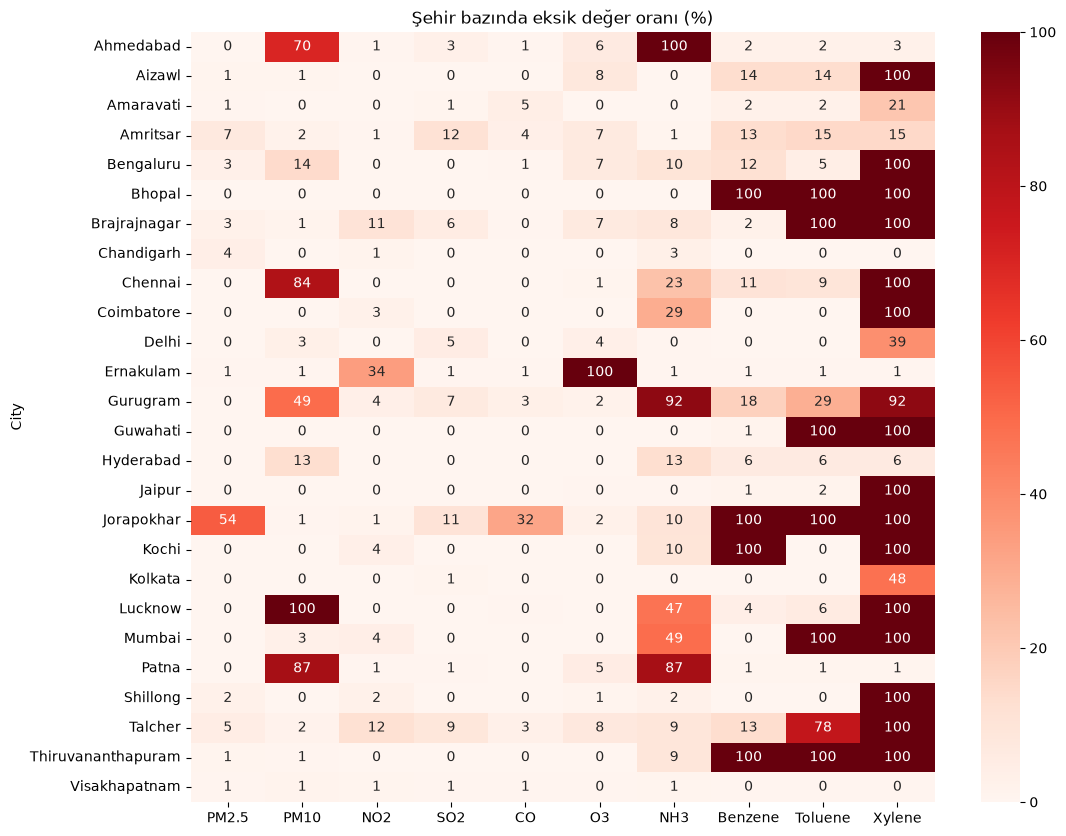

In [56]:
# eksik değer ısı haritası

miss_city = df_india.groupby("City")[["PM2.5","PM10","NO2","SO2","CO","O3","NH3","Benzene","Toluene","Xylene"]].apply(lambda group: group.isnull().mean() * 100)

plt.figure(figsize=(12,10))
sns.heatmap(miss_city, annot=True, fmt=".0f", cmap="Reds")
plt.title("Şehir bazında eksik değer oranı (%)")
plt.show()

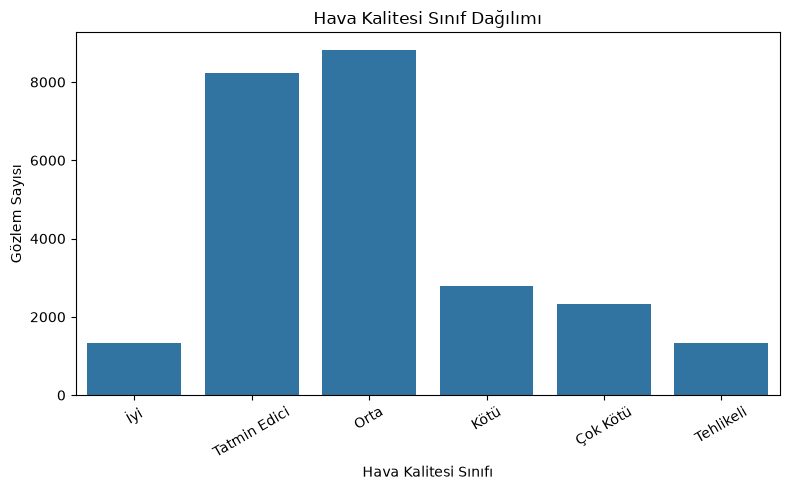

In [57]:
# Sınıf isimlerini Türkçeye çevir
tr_sinif ={
    "Good": "İyi",
    "Satisfactory": "Tatmin Edici",
    "Moderate": "Orta",
    "Poor": "Kötü",
    "Very Poor": "Çok Kötü",
    "Severe": "Tehlikeli"
}

df_india["AQI_Bucket"] = df_india["AQI_Bucket"].map(tr_sinif)

# Türkçe sınıf sıralaması
siniflar = ["İyi", "Tatmin Edici", "Orta", "Kötü", "Çok Kötü", "Tehlikeli"]

plt.figure(figsize=(8,5))
sns.countplot(data=df_india, x="AQI_Bucket", order=siniflar)
plt.title("Hava Kalitesi Sınıf Dağılımı")
plt.xlabel("Hava Kalitesi Sınıfı")
plt.ylabel("Gözlem Sayısı")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()